# 04 · Interaction discovery
Runs the real full stack (`synera_core.discovery.stack`) on the Track B dataset, then looks at the Track A gene-level result.

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from synera_core.config import find_repo_root, get_settings
warnings.filterwarnings("ignore")
ROOT = find_repo_root()
C = dict(bg="#061424", panel="#0b2037", cyan="#16B5FF", green="#6FD65B", amber="#FFB547", red="#FF4D5E", teal="#19E3B1", text="#EAF2FB", muted="#8FA6BF")
plt.rcParams.update({"figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "text.color": C["text"], "xtick.color": C["muted"], "ytick.color": C["muted"], "grid.color": "#1c3a5c", "axes.grid": True, "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=[C["cyan"], C["green"], C["amber"], C["red"], C["teal"]]), "figure.dpi": 110, "font.size": 9})
SEED = get_settings().seeds.global_seed
RES = ROOT / "artifacts" / "results"

In [2]:
from synera_core.discovery.stack import run_full_stack
from synera_core.pipeline.registry import get_spec, load_panel
from synera_core.benchmark.generator import STRESSORS
df = load_panel(get_spec("benchmark_track_b"))
res = run_full_stack(df, "outcome", STRESSORS, n_boot=99, n_ci=60, seed=SEED)
print("rows", res["n_rows"], "block length", res["block_len"], "days;", res["stage_counts"], f"{res['runtime_s']['total']:.0f}s")
P = pd.DataFrame(res["pairs"]); display(P[P.s3_conditional][["a","b","type","effect_size","q_boot","gbm_rank","nid_rank","final"]].round(4))

rows 4122 block length 22 days; {'marginal_bh': 43, 'after_forward': 3, 'after_backward': 3} 24s


,a,b,type,effect_size,q_boot,gbm_rank,nid_rank,final
0,heat_index,pm25,SYNERGISTIC,0.3164,0.0,4,2,True
1,heat_index,rh,ANTAGONISTIC,0.2970,0.0,2,1,True
2,heat_index,o3,NONLINEAR,0.2292,0.0,1,5,True


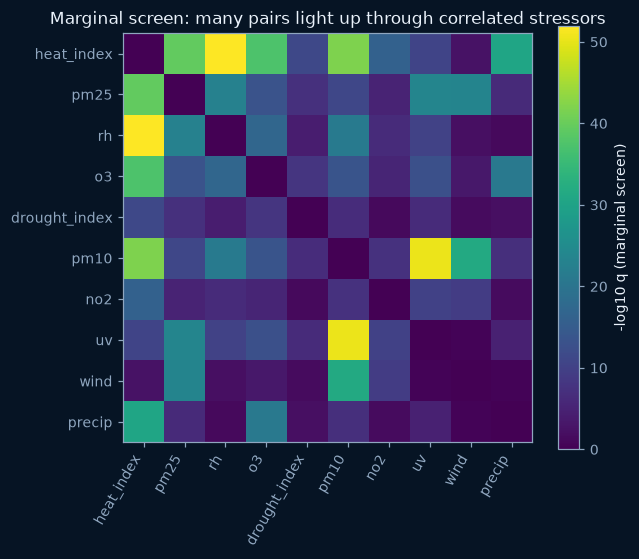

In [3]:
from synera_core.discovery.stack import nuisance_frame
S = list(STRESSORS); M = np.zeros((len(S), len(S)))
for r in res["pairs"]:
    i, j = S.index(r["a"]), S.index(r["b"]); M[i, j] = M[j, i] = -np.log10(max(r["q_boot"], 1e-300))
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(M, cmap="viridis"); ax.set_xticks(range(len(S)), S, rotation=60, ha="right"); ax.set_yticks(range(len(S)), S); ax.grid(False)
plt.colorbar(im, label="-log10 q (marginal screen)"); ax.set_title("Marginal screen: many pairs light up through correlated stressors"); plt.show()

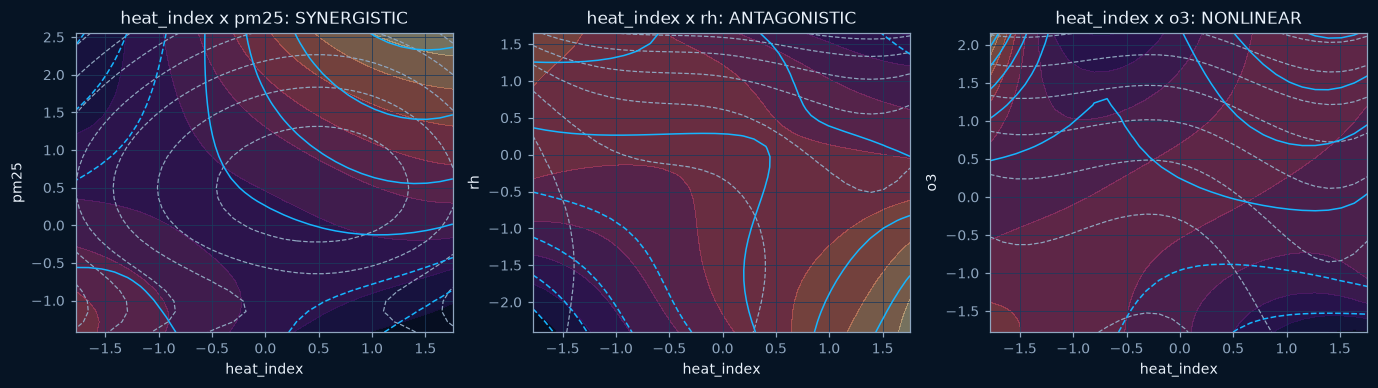

In [4]:
acc = [r for r in res["pairs"] if r["s3_conditional"]]
fig, axes = plt.subplots(1, max(len(acc), 1), figsize=(4.2 * max(len(acc), 1), 3.6), squeeze=False)
for ax, r in zip(axes[0], acc):
    s = r["surface"]; ga, gb = np.array(s["grid_a"]), np.array(s["grid_b"])
    ax.contour(ga, gb, np.array(s["z_additive"]), colors=C["muted"], linestyles="--", linewidths=0.8)
    cs = ax.contour(ga, gb, np.array(s["z_full"]), colors=C["cyan"], linewidths=1.0); ax.contourf(ga, gb, np.array(s["z_gap"]), levels=8, cmap="magma", alpha=0.45)
    ax.set_xlabel(r["a"]); ax.set_ylabel(r["b"]); ax.set_title(f"{r['a']} x {r['b']}: {r['type']}")
plt.tight_layout(); plt.show()

## Track A: gene-level interaction (REAL NASA data)
No gene passes FDR; the volcano is an exploratory ranking.

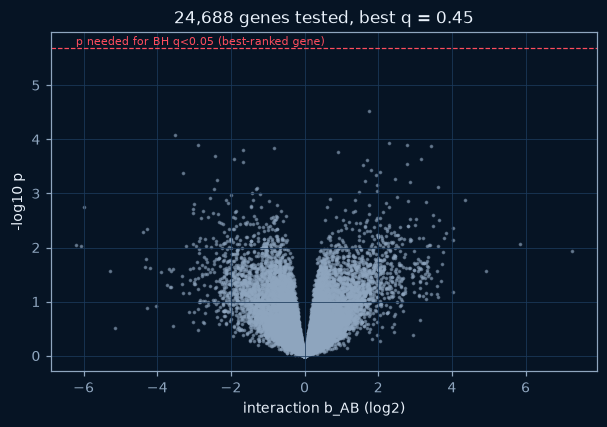

,gene_symbol,b_AB,p,q
0,Gm11520,1.7530,0.000029,0.449039
1,Igkv6-23,-3.5164,0.000082,0.449039
2,Gm50169,2.2987,0.000115,0.449039
3,Rtl9,2.7847,0.000126,0.449039
4,Gm54611,-2.8935,0.000127,0.449039
5,Gm15886,3.4410,0.000132,0.449039
6,Slc25a14,-0.8267,0.000146,0.449039
7,Gm50103,-1.6620,0.000160,0.449039
8,2610005L07Rik,0.9163,0.000173,0.449039
9,ENSMUSG00000044387,-2.4431,0.000200,0.449039


In [5]:
G = json.loads((RES / "osdr_genes.json").read_text()); g = pd.DataFrame(G)
fig, ax = plt.subplots(figsize=(6.4, 4)); ax.scatter(g.b_AB, g.neg_log10_p, s=2, c=C["muted"], alpha=0.5)
ax.axhline(-np.log10(0.05 / len(g)), color=C["red"], ls="--", lw=0.8); ax.text(g.b_AB.min(), -np.log10(0.05 / len(g)) + 0.05, "p needed for BH q<0.05 (best-ranked gene)", color=C["red"], fontsize=7)
ax.set_xlabel("interaction b_AB (log2)"); ax.set_ylabel("-log10 p"); ax.set_title(f"{len(g):,} genes tested, best q = {g.q.min():.2f}"); plt.show()
display(g.head(10)[["gene_symbol", "b_AB", "p", "q"]])